In [19]:

import os
import re
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


os.makedirs("figures", exist_ok=True)

print("All tools loaded.")

All tools loaded.


In [20]:

from urllib.parse import urljoin

BASE_URL = "https://books.toscrape.com/"
HEADERS = {"User-Agent": "Mozilla/5.0 (student project)"}


home_html = requests.get(BASE_URL, headers=HEADERS).text
home_soup = BeautifulSoup(home_html, "html.parser")


category_links = home_soup.select("div.side_categories ul li a")


category_links = category_links[1:]

categories = []
for link in category_links:
    name = link.get_text(strip=True)
    url = urljoin(BASE_URL, link["href"])
    categories.append((name, url))

print("Categories found:", len(categories))
for name, url in categories[:5]:
    print(name, "->", url)

Categories found: 50
Travel -> https://books.toscrape.com/catalogue/category/books/travel_2/index.html
Mystery -> https://books.toscrape.com/catalogue/category/books/mystery_3/index.html
Historical Fiction -> https://books.toscrape.com/catalogue/category/books/historical-fiction_4/index.html
Sequential Art -> https://books.toscrape.com/catalogue/category/books/sequential-art_5/index.html
Classics -> https://books.toscrape.com/catalogue/category/books/classics_6/index.html


In [21]:



books = []

for category_name, category_url in categories:
    page_url = category_url
    page_number = 1

    while page_url:
        # Open the current page
        page_html = requests.get(page_url, headers=HEADERS).text
        page_soup = BeautifulSoup(page_html, "html.parser")

        # Each book is inside an <article class="product_pod">
        for card in page_soup.select("article.product_pod"):
            title = card.h3.a["title"]
            price_text = card.select_one("p.price_color").get_text(strip=True)
            rating_word = card.select_one("p.star-rating")["class"][1]
            stock_text = card.select_one("p.instock.availability").get_text(strip=True)
            book_link = card.h3.a["href"]

            books.append({
                "category": category_name,
                "title": title,
                "price_text": price_text,
                "rating_word": rating_word,
                "stock_text": stock_text,
                "product_url": urljoin(page_url, book_link)
            })

        # Check if there is a "next" button
        next_button = page_soup.select_one("li.next a")
        if next_button:
            page_url = urljoin(page_url, next_button["href"])
            page_number += 1
        else:
            page_url = None

    print(category_name, "done -", page_number, "page(s)")

print("Total books found:", len(books))

Travel done - 1 page(s)
Mystery done - 2 page(s)
Historical Fiction done - 2 page(s)
Sequential Art done - 4 page(s)
Classics done - 1 page(s)
Philosophy done - 1 page(s)
Romance done - 2 page(s)
Womens Fiction done - 1 page(s)
Fiction done - 4 page(s)
Childrens done - 2 page(s)
Religion done - 1 page(s)
Nonfiction done - 6 page(s)
Music done - 1 page(s)
Default done - 8 page(s)
Science Fiction done - 1 page(s)
Sports and Games done - 1 page(s)
Add a comment done - 4 page(s)
Fantasy done - 3 page(s)
New Adult done - 1 page(s)
Young Adult done - 3 page(s)
Science done - 1 page(s)
Poetry done - 1 page(s)
Paranormal done - 1 page(s)
Art done - 1 page(s)
Psychology done - 1 page(s)
Autobiography done - 1 page(s)
Parenting done - 1 page(s)
Adult Fiction done - 1 page(s)
Humor done - 1 page(s)
Horror done - 1 page(s)
History done - 1 page(s)
Food and Drink done - 2 page(s)
Christian Fiction done - 1 page(s)
Business done - 1 page(s)
Biography done - 1 page(s)
Thriller done - 1 page(s)
Contem

In [22]:

for i, book in enumerate(books):
    page_html = requests.get(book["product_url"], headers=HEADERS).text
    soup = BeautifulSoup(page_html, "html.parser")

   
    description = ""
    desc_header = soup.find("div", id="product_description")
    if desc_header is not None:
        desc_paragraph = desc_header.find_next_sibling("p")
        if desc_paragraph is not None:
            description = desc_paragraph.get_text(strip=True)
    book["description"] = description

   
    quantity = None
    stock_block = soup.select_one("p.instock.availability")
    if stock_block is not None:
        match = re.search(r"\((\d+) available\)", stock_block.get_text())
        if match:
            quantity = int(match.group(1))
    book["stock_quantity"] = quantity

   
    time.sleep(0.1)

    if (i + 1) % 100 == 0:
        print("Checked", i + 1, "book pages")

print("Finished. Total books:", len(books))

Checked 100 book pages
Checked 200 book pages
Checked 300 book pages
Checked 400 book pages
Checked 500 book pages
Checked 600 book pages
Checked 700 book pages
Checked 800 book pages
Checked 900 book pages
Checked 1000 book pages
Finished. Total books: 1000


In [23]:

raw_df = pd.DataFrame(books)


raw_df.to_csv("books_toscrape_raw.csv", index=False)

print("Raw dataset shape:", raw_df.shape)
raw_df.head()

Raw dataset shape: (1000, 8)


,category,title,price_text,rating_word,stock_text,product_url,description,stock_quantity
0,Travel,It's Only the Himalayas,Â£45.17,Two,In stock,https://books.toscrape.com/catalogue/its-only-...,"âWherever you go, whatever you do, just . . ...",19
1,Travel,Full Moon over Noahâs Ark: An Odyssey to Mou...,Â£49.43,Four,In stock,https://books.toscrape.com/catalogue/full-moon...,Acclaimed travel writer Rick Antonson sets his...,15
2,Travel,See America: A Celebration of Our National Par...,Â£48.87,Three,In stock,https://books.toscrape.com/catalogue/see-ameri...,To coincide with the 2016 centennial anniversa...,14
3,Travel,Vagabonding: An Uncommon Guide to the Art of L...,Â£36.94,Two,In stock,https://books.toscrape.com/catalogue/vagabondi...,With a new foreword by Tim Ferriss â¢Thereâ...,8
4,Travel,Under the Tuscan Sun,Â£37.33,Three,In stock,https://books.toscrape.com/catalogue/under-the...,A CLASSIC FROM THE BESTSELLING AUTHOR OF UNDER...,7


 2. Data Cleaning
This is where we begin cleaning the raw data into numbers that we will use for charts and models.

In [24]:



raw_df['price'] = raw_df['price_text'].str.replace(r'[^\d.]', '', regex=True).astype(float)


rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
raw_df['rating'] = raw_df['rating_word'].map(rating_map)


raw_df['availability'] = raw_df['stock_text'].apply(lambda x: 1 if "In stock" in x else 0)


raw_df['stock_quantity'] = raw_df['stock_quantity'].fillna(0).astype(int)


raw_df['description_word_count'] = raw_df['description'].astype(str).apply(lambda x: len(x.split()))


clean_df = raw_df.drop(columns=['price_text', 'rating_word', 'stock_text', 'product_url', 'description'])


clean_df.to_csv("books_toscrape_clean.csv", index=False)

print("Cleaning finished! Here is the clean data:")
clean_df.head()

Cleaning finished! Here is the clean data:


,category,title,stock_quantity,price,rating,availability,description_word_count
0,Travel,It's Only the Himalayas,19,45.17,2,1,230
1,Travel,Full Moon over Noahâs Ark: An Odyssey to Mou...,15,49.43,4,1,284
2,Travel,See America: A Celebration of Our National Par...,14,48.87,3,1,145
3,Travel,Vagabonding: An Uncommon Guide to the Art of L...,8,36.94,2,1,334
4,Travel,Under the Tuscan Sun,7,37.33,3,1,166


 3. Data Visualization
Here we creating charts to see what affects book prices.

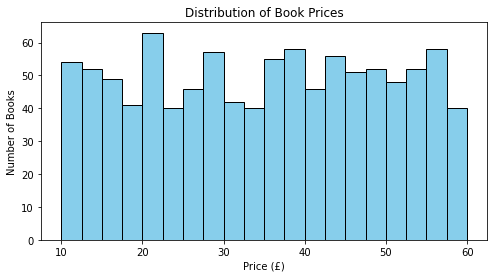

In [25]:

plt.figure(figsize=(8, 4))
plt.hist(clean_df['price'], bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Book Prices')
plt.xlabel('Price (£)')
plt.ylabel('Number of Books')
plt.savefig('figures/fig1_price_distribution.png', bbox_inches='tight')
plt.show()

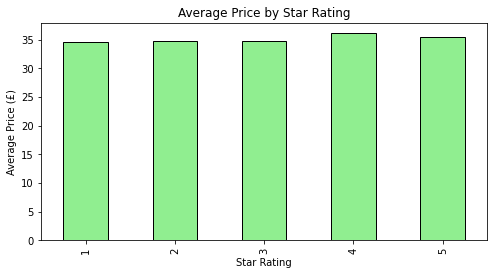

In [26]:

plt.figure(figsize=(8, 4))
clean_df.groupby('rating')['price'].mean().plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('Average Price by Star Rating')
plt.xlabel('Star Rating')
plt.ylabel('Average Price (£)')
plt.savefig('figures/fig2_price_by_rating.png', bbox_inches='tight')
plt.show()

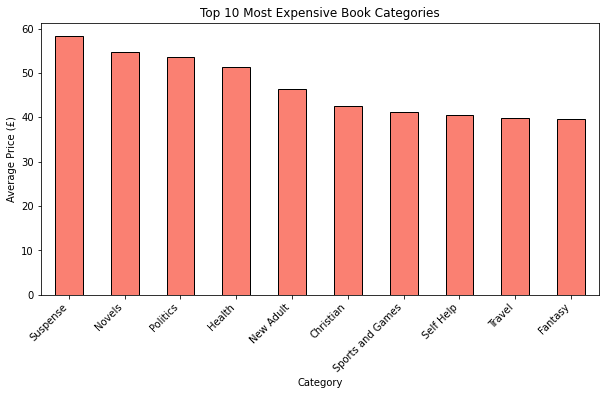

In [15]:


top_categories = clean_df.groupby('category')['price'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_categories.plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Top 10 Most Expensive Book Categories')
plt.xlabel('Category')
plt.ylabel('Average Price (£)')
plt.xticks(rotation=45, ha='right')
plt.savefig('figures/fig3_top_categories.png', bbox_inches='tight')
plt.show()

4. Linear Regression Model
Building a model to predict the price using the rating, category, and stock.

In [16]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error



model_df = pd.get_dummies(clean_df, columns=['category'], drop_first=True)


X = model_df.drop(columns=['title', 'price'])
y = model_df['price']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data is ready for the model!")
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Data is ready for the model!
Training rows: 800
Testing rows: 200


In [18]:



model = LinearRegression()
model.fit(X_train, y_train)


predictions = model.predict(X_test)


r2 = r2_score(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("=== MODEL RESULTS ===")
print("R-squared (Accuracy):", round(r2, 3))
print("Mean Absolute Error (MAE): £", round(mae, 2))
print("Root Mean Squared Error (RMSE): £", round(rmse, 2))

=== MODEL RESULTS ===
R-squared (Accuracy): -0.107
Mean Absolute Error (MAE): £ 12.62
Root Mean Squared Error (RMSE): £ 15.1


 5. Summary and Interpretation: 

The linear regression model achieved an R-squared of -0.107, an MAE of £12.62, and an RMSE of £15.10. 

Because the R-squared isn't positive, but rather is negative, it means that a book's star rating, category, and stock quantity are not strong predictors of its price. The model is guessing worse than simply predicting the average price for every book. 

*The why?*
In the real world, book prices are likely affected by other factors we did not look into, such as page count, publisher, book type (hardcover vs. paperback), or when the book was published. This is a key restriction of the dataset and the linear regression model.